In [10]:
!ls

Dataset  Dataset.zip  sample_data  src	src.zip


In [ ]:
!unzip

Archive:  Dataset.zip
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of Dataset.zip or
        Dataset.zip.zip, and cannot find Dataset.zip.ZIP, period.


In [ ]:
!unzip src.zip

Archive:  src.zip
   creating: src/
  inflating: src/brief_pattern.h     
  inflating: src/common.h            
  inflating: src/cuda_utils.cuh      
  inflating: src/main.cu             
  inflating: src/stb_image.h         
  inflating: src/stb_image_write.h   
  inflating: src/stb_impl.cpp        
  inflating: src/stb_sources.json    
  inflating: src/tests.cpp           
  inflating: src/THIRD_PARTY_LICENSES.md  
   creating: src/v0/
  inflating: src/v0/descriptor.cpp   
  inflating: src/v0/detector.cpp     
  inflating: src/v0/homography.cpp   
  inflating: src/v0/matching.cpp     
  inflating: src/v0/pipeline.cpp     
  inflating: src/v0/preprocess.cpp   
  inflating: src/v0/warp_blend.cpp   
  inflating: src/versions.h          
   creating: src/__pycache__/
  inflating: src/__pycache__/run.cpython-314.pyc  


## Chuẩn bị môi trường

In [11]:
from pathlib import Path
import os

paths = [Path.cwd(), Path.cwd() / "Midterm",
         Path("/content/CSC14120-Parallel-Programming/Midterm")]
base = next(path for path in paths if (path / "src/common.h").is_file())
os.chdir(base)
data = Path(os.environ.get("PANORAMA_DATASET", "Dataset"))
if not data.is_dir():
    data = Path("Dataset")
assert data.is_dir(), "Chưa có thư mục Dataset"
os.environ["PANORAMA_DATASET"] = str(data.resolve())
Path("build").mkdir(exist_ok=True)
Path("outputs").mkdir(exist_ok=True)

In [12]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

out = Path("outputs")

In [ ]:
!g++ --version
!nvcc --version

g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
Copyright (C) 2023 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Wed_Aug_20_01:58:59_PM_PDT_2025
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0


# Run

In [14]:
%%bash
set -eu
g++ -O2 -std=c++17 -c src/stb_impl.cpp -o build/stb_impl.o
for file in src/v0/*.cpp; do
    name=$(basename "$file" .cpp)
    g++ -O2 -std=c++17 -c "$file" -o "build/v0_${name}.o"
done

In [ ]:
!nvcc -O2 -std=c++17 -c src/main.cu -o build/main.o

In [ ]:
!nvcc build/main.o build/stb_impl.o build/v0_*.o -o stitch

In [ ]:
!g++ -O2 -std=c++17 src/tests.cpp build/v0_*.o -o tests

# Method

| Bước | Phương pháp | Tham số và lý do chọn |
|---|---|---|
| Tiền xử lý | Ảnh xám và Gaussian tách hai chiều | Ảnh xám chuẩn hóa về [0,1]; sigma 1, √2, 2, 2√2, 4. Giảm nhiễu trước khi tìm điểm. |
| Phát hiện điểm | DoG, cực trị trong vùng 3×3×3 | Ngưỡng tương phản 0.03; loại cạnh bằng Hessian; giữ tối đa 4000 điểm có đáp ứng lớn. |
| Mô tả điểm | BRIEF 256 bit | So sánh 256 cặp điểm trong vùng 31×31. Mẫu cố định với seed 21; bỏ điểm quá gần biên. |
| Ghép điểm | Khoảng cách Hamming và ratio test | Tìm hai ứng viên gần nhất; nhận khi khoảng cách nhỏ nhất < 0.8 lần khoảng cách thứ hai. |
| Homography | RANSAC và normalized DLT | 2000 lần lấy mẫu, mỗi mẫu bốn cặp điểm; ngưỡng inlier 3 pixel; tính lại H từ các inlier. |
| Biến đổi, hòa trộn | Warp ngược, nội suy song tuyến và feather blending | Tính canvas từ các góc ảnh; trộn theo khoảng cách tới biên ảnh. Pixel màu đen vẫn được xem là dữ liệu hợp lệ. |

Gaussian là phép tính theo từng pixel; BRIEF và matching có thể chia việc theo điểm đặc trưng. Các giả thuyết RANSAC độc lập với nhau, còn warp ghi một pixel đầu ra cho mỗi tác vụ. Đây là những phần có thể đưa lên GPU ở các phiên bản sau.

Các thay đổi so với ParaPano: dùng Gaussian tách hai chiều với ít mức hơn; kiểm tra cực trị đầy đủ qua không gian và mức ảnh; thêm top-K; tăng vùng BRIEF; tự viết bộ giải homography và warp thay cho OpenCV. 

Bộ giải DLT dùng Jacobi trên AᵀA sau chuẩn hóa tọa độ. Cách này có hạn chế về độ ổn định số so với SVD trực tiếp. BRIEF hiện chưa bù xoay; homography cũng không xử lý được mọi sai lệch do parallax.

### Bộ ảnh 1

In [24]:
%%bash
set -eu
for size in 1280x720 1920x1080 3840x2160; do
    name="image1_${size}"
    if ./stitch "$PANORAMA_DATASET/image1_left_${size}.jpg" "$PANORAMA_DATASET/image1_right_${size}.jpg" "outputs/${name}.png" --version 0 --runs 5 --metrics "outputs/${name}.json" > "outputs/${name}.log" 2>&1; then
        echo ok > "outputs/${name}.status"
    else
        echo error > "outputs/${name}.status"
    fi
    echo "$name"
    cat "outputs/${name}.log"
done

image1_1280x720
V0 CPU, 5 timed runs after warm-up
Stage 1: 447.06 ms
Stage 2: 36.8258 ms
Stage 3: 8.19484 ms
Stage 4: 350.002 ms
Stage 5: 84.9615 ms
Stage 6: 162.284 ms
End-to-end excluding disk I/O: 1089.34 ms
image1_1920x1080
V0 CPU, 5 timed runs after warm-up
Stage 1: 1001.97 ms
Stage 2: 93.693 ms
Stage 3: 15.7004 ms
Stage 4: 1116.62 ms
Stage 5: 96.9674 ms
Stage 6: 360.901 ms
End-to-end excluding disk I/O: 2685.86 ms
image1_3840x2160
V0 CPU, 5 timed runs after warm-up
Stage 1: 4087.95 ms
Stage 2: 428.555 ms
Stage 3: 26.28 ms
Stage 4: 2913.93 ms
Stage 5: 117.52 ms
Stage 6: 1361.81 ms
End-to-end excluding disk I/O: 8943.19 ms


### Bộ ảnh 2

In [25]:
%%bash
set -eu
for size in 1280x720 1920x1080 3840x2160; do
    name="image2_${size}"
    if ./stitch "$PANORAMA_DATASET/image2_left_${size}.jpg" "$PANORAMA_DATASET/image2_mid_${size}.jpg" "outputs/${name}.png" --version 0 --runs 5 --metrics "outputs/${name}.json" > "outputs/${name}.log" 2>&1; then
        echo ok > "outputs/${name}.status"
    else
        echo error > "outputs/${name}.status"
    fi
    echo "$name"
    cat "outputs/${name}.log"
done

image2_1280x720
V0 CPU, 5 timed runs after warm-up
Stage 1: 384.806 ms
Stage 2: 40.6422 ms
Stage 3: 11.6286 ms
Stage 4: 738.17 ms
Stage 5: 63.1968 ms
Stage 6: 115.328 ms
End-to-end excluding disk I/O: 1353.78 ms
image2_1920x1080
V0 CPU, 5 timed runs after warm-up
Stage 1: 1023.33 ms
Stage 2: 107.062 ms
Stage 3: 23.3057 ms
Stage 4: 2348.27 ms
Stage 5: 71.6878 ms
Stage 6: 293.133 ms
End-to-end excluding disk I/O: 3870.62 ms
image2_3840x2160
V0 CPU, 5 timed runs after warm-up
Stage 1: 3806.76 ms
Stage 2: 502.122 ms
Stage 3: 28.5529 ms
Stage 4: 2864.46 ms
Stage 5: 81.316 ms
Stage 6: 1269.29 ms
End-to-end excluding disk I/O: 8566.06 ms


### Bộ ảnh 3

In [26]:
%%bash
set -eu
for size in 1280x720 1920x1080 3840x2160; do
    name="image3_${size}"
    if ./stitch "$PANORAMA_DATASET/image3_left_${size}.jpg" "$PANORAMA_DATASET/image3_right_${size}.jpg" "outputs/${name}.png" --version 0 --runs 5 --metrics "outputs/${name}.json" > "outputs/${name}.log" 2>&1; then
        echo ok > "outputs/${name}.status"
    else
        echo error > "outputs/${name}.status"
    fi
    echo "$name"
    cat "outputs/${name}.log"
done

image3_1280x720
V0 CPU, 5 timed runs after warm-up
Stage 1: 380.287 ms
Stage 2: 47.2123 ms
Stage 3: 10.9231 ms
Stage 4: 676.183 ms
Stage 5: 67.1737 ms
Stage 6: 115.51 ms
End-to-end excluding disk I/O: 1297.3 ms
image3_1920x1080
V0 CPU, 5 timed runs after warm-up
Stage 1: 872.367 ms
Stage 2: 107.902 ms
Stage 3: 22.9772 ms
Stage 4: 2768.91 ms
Stage 5: 82.3644 ms
Stage 6: 287.543 ms
End-to-end excluding disk I/O: 4142.07 ms
image3_3840x2160
V0 CPU, 5 timed runs after warm-up
Stage 1: 3719.1 ms
Stage 2: 545.288 ms
Stage 3: 28.172 ms
Stage 4: 2897.25 ms
Stage 5: 73.1473 ms
Stage 6: 1069.25 ms
End-to-end excluding disk I/O: 8340.52 ms


### Bộ ảnh 4

In [27]:
%%bash
set -eu
for size in 1280x720 1920x1080 3840x2160; do
    name="image4_${size}"
    if ./stitch "$PANORAMA_DATASET/image4_left_${size}.jpg" "$PANORAMA_DATASET/image4_right_${size}.jpg" "outputs/${name}.png" --version 0 --runs 5 --metrics "outputs/${name}.json" > "outputs/${name}.log" 2>&1; then
        echo ok > "outputs/${name}.status"
    else
        echo error > "outputs/${name}.status"
    fi
    echo "$name"
    cat "outputs/${name}.log"
done

image4_1280x720
V0 CPU, 5 timed runs after warm-up
Stage 1: 380.752 ms
Stage 2: 34.5406 ms
Stage 3: 8.95592 ms
Stage 4: 400.091 ms
Stage 5: 60.9203 ms
Stage 6: 139.517 ms
End-to-end excluding disk I/O: 1024.79 ms
image4_1920x1080
V0 CPU, 5 timed runs after warm-up
Stage 1: 945.788 ms
Stage 2: 101.737 ms
Stage 3: 21.0942 ms
Stage 4: 2316.84 ms
Stage 5: 70.5091 ms
Stage 6: 540.831 ms
End-to-end excluding disk I/O: 3999.12 ms
image4_3840x2160
Error: Horizon crosses image B


## Bảng thời gian
Đọc các kết quả của lần chạy trên và trường hợp thất bại 

In [28]:
results, failures = [], []
for path in sorted(out.glob("image[1-4]_*.status")):
    site, size = path.stem.split("_", 1)
    if path.read_text().strip() == "ok":
        result = json.loads(path.with_suffix(".json").read_text())
        result.update(site=site, size=size)
        results.append(result)
    else:
        error = path.with_suffix(".log").read_text()
        failures.append({"Bộ ảnh": site, "Kích thước": size, "Lỗi": error.strip()})
display(pd.DataFrame(failures))

,Bộ ảnh,Kích thước,Lỗi
0,image4,3840x2160,Error: Horizon crosses image B


In [29]:
rows = []
for result in results:
    row = {"Bộ ảnh": result["site"], "Kích thước": result["size"],
           "Trung bình (ms)": result["mean_ms"], "Nhỏ nhất (ms)": result["min_ms"],
           "Độ lệch chuẩn (ms)": result["stddev_ms"]}
    for i, value in enumerate(result["stage_mean_ms"], 1):
        row[f"Bước {i} (ms)"] = value
    rows.append(row)
timing = pd.DataFrame(rows)
display(timing.round(2))
timing.to_csv(out / "timing.csv", index=False, encoding="utf-8-sig")

,Bộ ảnh,Kích thước,Trung bình (ms),Nhỏ nhất (ms),Độ lệch chuẩn (ms),Bước 1 (ms),Bước 2 (ms),Bước 3 (ms),Bước 4 (ms),Bước 5 (ms),Bước 6 (ms)
0,image1,1280x720,1089.34,970.91,205.47,447.06,36.83,8.19,350.00,84.96,162.28
1,image1,1920x1080,2685.86,2446.79,443.86,1001.97,93.69,15.70,1116.62,96.97,360.90
2,image1,3840x2160,8943.19,8254.19,637.56,4087.95,428.56,26.28,2913.93,117.52,1361.81
3,image2,1280x720,1353.78,1329.09,25.78,384.81,40.64,11.63,738.17,63.20,115.33
4,image2,1920x1080,3870.62,3634.49,279.66,1023.33,107.06,23.31,2348.27,71.69,293.13
5,image2,3840x2160,8566.06,8099.01,344.42,3806.76,502.12,28.55,2864.46,81.32,1269.29
6,image3,1280x720,1297.30,1283.27,13.42,380.29,47.21,10.92,676.18,67.17,115.51
7,image3,1920x1080,4142.07,3964.00,249.29,872.37,107.90,22.98,2768.91,82.36,287.54
8,image3,3840x2160,8340.52,7793.04,485.30,3719.10,545.29,28.17,2897.25,73.15,1069.25
9,image4,1280x720,1024.79,1012.49,16.36,380.75,34.54,8.96,400.09,60.92,139.52


## Phân bố thời gian theo bước

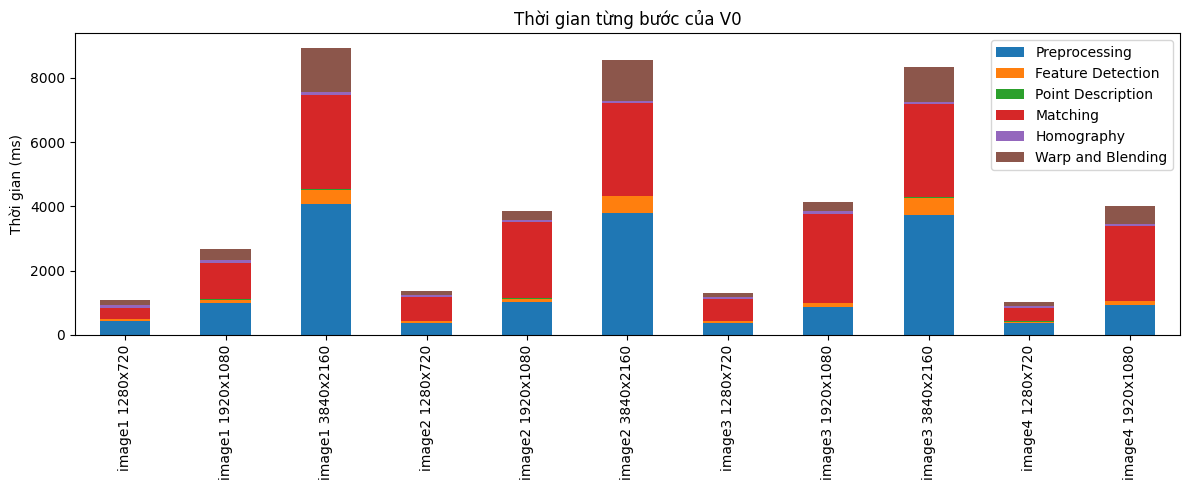

In [38]:
stage_names = ["Preprocessing", "Feature Detection", "Point Description", "Matching", "Homography", "Warp and Blending"]
stage_times = pd.DataFrame([r["stage_mean_ms"] for r in results], columns=stage_names,
                           index=[r["site"] + " " + r["size"] for r in results])
stage_times.plot.bar(stacked=True, figsize=(12, 5))
plt.ylabel("Thời gian (ms)")
plt.title("Thời gian từng bước của V0")
plt.tight_layout()
plt.show()

In [31]:
for result in results:
    times = np.array(result["stage_mean_ms"])
    largest = times.argmax()
    print(f"{result['site']} {result['size']}: {stage_names[largest]} chiếm {times[largest] / times.sum():.1%}")

image1 1280x720: Preprocessing chiếm 41.0%
image1 1920x1080: Point Matching chiếm 41.6%
image1 3840x2160: Preprocessing chiếm 45.7%
image2 1280x720: Point Matching chiếm 54.5%
image2 1920x1080: Point Matching chiếm 60.7%
image2 3840x2160: Preprocessing chiếm 44.5%
image3 1280x720: Point Matching chiếm 52.1%
image3 1920x1080: Point Matching chiếm 66.8%
image3 3840x2160: Preprocessing chiếm 44.6%
image4 1280x720: Point Matching chiếm 39.0%
image4 1920x1080: Point Matching chiếm 58.0%


In [33]:
all_stages = []
for result in results:
    p = sum(result["stage_mean_ms"]) / result["mean_ms"]
    limit = 1 / (1 - p) if p < 1 else np.inf
    all_stages.append({"Bộ ảnh": result["site"], "Kích thước": result["size"],
                       "p (sáu bước)": p, "Giới hạn lý tưởng": limit})
display(pd.DataFrame(all_stages).round(3))

,Bộ ảnh,Kích thước,p (sáu bước),Giới hạn lý tưởng
0,image1,1280x720,1.000,106852.381
1,image1,1920x1080,1.000,253536.109
2,image1,3840x2160,0.999,1251.494
3,image2,1280x720,1.000,138579.319
4,image2,1920x1080,0.999,1009.704
5,image2,3840x2160,0.998,631.571
6,image3,1280x720,1.000,129701.387
7,image3,1920x1080,1.000,462232.955
8,image3,3840x2160,0.999,1001.751
9,image4,1280x720,1.000,107595.900


## Panorama

### Kết quả bộ 1

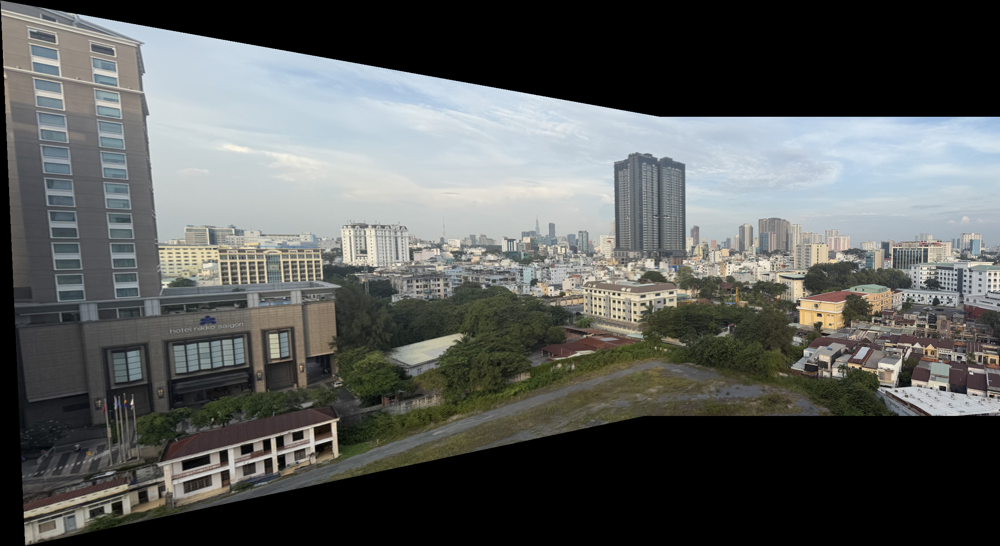

In [34]:
path = out / "image1_1280x720.png"
if path.exists():
    image = Image.open(path)
    image.thumbnail((1000, 600))
    display(image)

### Kết quả bộ 2

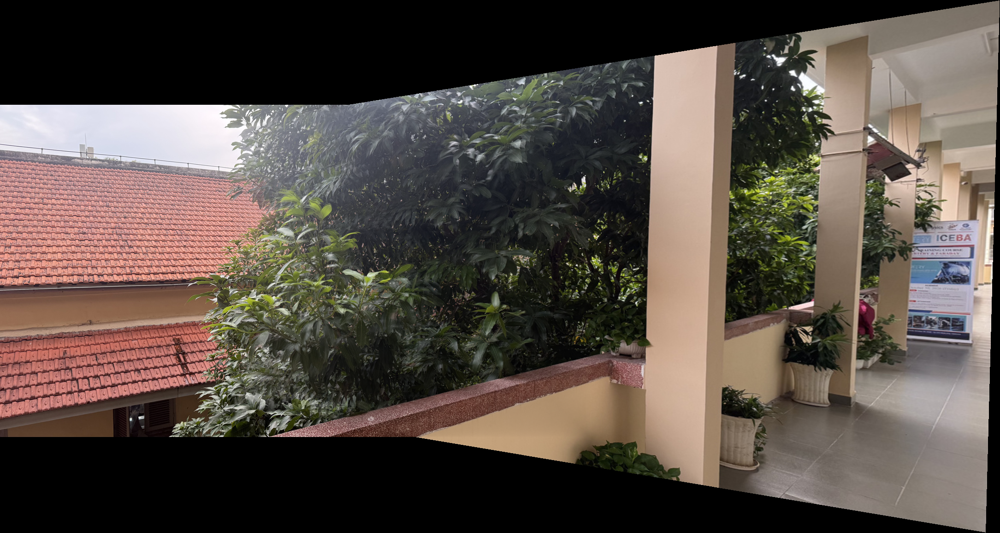

In [35]:
path = out / "image2_1280x720.png"
if path.exists():
    image = Image.open(path)
    image.thumbnail((1000, 600))
    display(image)

### Kết quả bộ 3

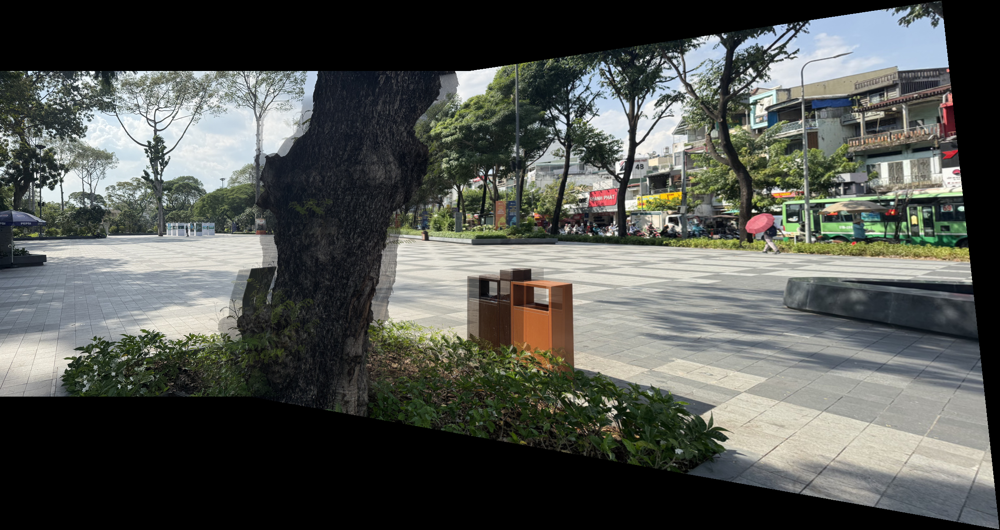

In [36]:
path = out / "image3_1280x720.png"
if path.exists():
    image = Image.open(path)
    image.thumbnail((1000, 600))
    display(image)

### Kết quả bộ 4

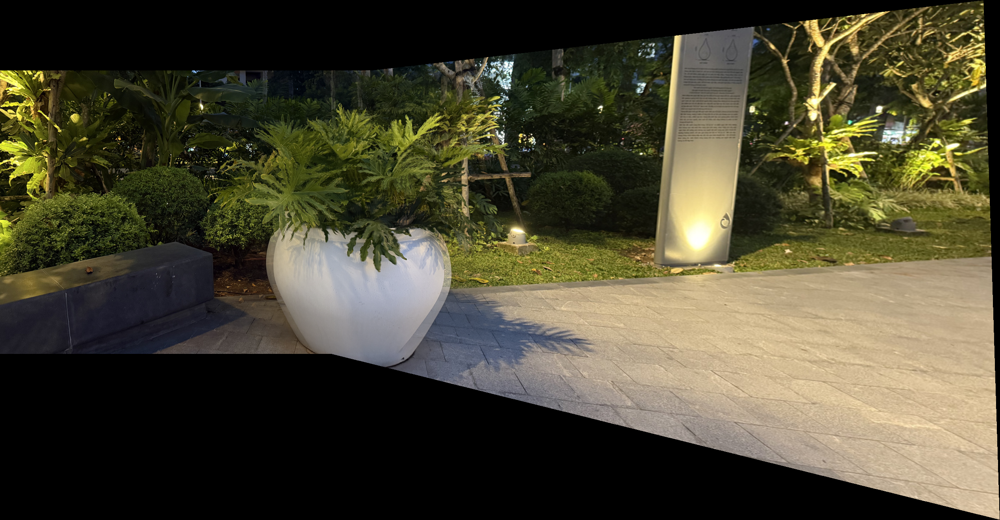

In [37]:
path = out / "image4_1280x720.png"
if path.exists():
    image = Image.open(path)
    image.thumbnail((1000, 600))
    display(image)

# Kế hoạch GPU

| Bước | Cách chia việc ở V1 | Điểm cần chú ý |
|---|---|---|
| Tiền xử lý | Một thread cho một pixel trong mỗi lượt lọc | Biên vùng lọc và lượng truy cập bộ nhớ |
| Phát hiện điểm | Một thread cho một pixel ở một mức ảnh | Thu gọn kết quả và chọn top-K |
| Mô tả điểm | Một thread cho một keypoint | Truy cập các vị trí trong vùng lân cận |
| Ghép điểm | Một thread cho một descriptor cần tìm ứng viên | Số phép so sánh lớn |
| Homography | Một block cho một giả thuyết RANSAC | Bộ giải ma trận và cộng số inlier |
| Warp và trộn | Một thread cho một pixel đầu ra | Nội suy và kiểm tra biên |


# Tài liệu tham khảo
- Xin Xu, Zhuoqun Chen, [ParaPano](https://github.com/zq-chen/ParaPano): phương pháp Gaussian/DoG, BRIEF, matching và blending. Giấy phép nằm trong `src/THIRD_PARTY_LICENSES.md`.
- Calonder và cộng sự, *BRIEF: Binary Robust Independent Elementary Features*.
- Hartley và Zisserman, *Multiple View Geometry*: normalized DLT và homography.
- Sean Barrett và cộng sự, [stb](https://github.com/nothings/stb): đọc và ghi ảnh.
